# Spotify 2023: Audio features across stream levels

I wanted to look at the professor's suggestion of studying the audio features **conditional on stream level** instead of forcing a user-affinity response into the 2023 data.

The question I am looking at here is:

**Do the audio features look different, or relate to each other differently, for songs with different levels of streams?**

I kept the same 8 audio features from the earlier EDA: BPM, danceability, valence, energy, acousticness, instrumentalness, liveness, and speechiness.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
from scipy.stats import kruskal, rankdata, norm, chi2
from pathlib import Path

# Folder for any tables/figures I may want to use later
output_dir = Path("spotify_option1_outputs")
output_dir.mkdir(exist_ok=True)


## Load the data

If `spotify-2023.csv` is already in the Colab session, this will read it directly. Otherwise Colab will ask me to upload it.


In [2]:
data_file = Path("spotify-2023.csv")

if not data_file.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        data_file = Path(next(iter(uploaded)))
    except ImportError:
        data_file = Path("/mnt/data/spotify-2023.csv")

df = pd.read_csv(data_file, encoding="latin1")

print("Shape of the original data:", df.shape)
display(df.head())


Shape of the original data: (953, 24)


,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,43,263,45,10,826,125,B,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,48,126,58,14,382,92,C#,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,94,207,91,14,949,138,F,Major,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,1,2019,8,23,7858,100,800840817,116,207,125,12,548,170,A,Major,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,1,2023,5,18,3133,50,303236322,84,133,87,15,425,144,A,Minor,65,23,80,14,63,11,6


## Quick check of the variables I need

I only need `streams` and the 8 audio features for this part of the analysis.


In [3]:
features = [
    "bpm",
    "danceability_%",
    "valence_%",
    "energy_%",
    "acousticness_%",
    "instrumentalness_%",
    "liveness_%",
    "speechiness_%"
]

display(df[["track_name", "artist(s)_name", "streams"] + features].head())


,track_name,artist(s)_name,streams,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",141381703,125,80,89,83,31,0,8,4
1,LALA,Myke Towers,133716286,92,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,140003974,138,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,800840817,170,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,303236322,144,65,23,80,14,63,11,6


The `streams` column is not completely numeric, so I converted it first. One row could not be converted, so I left that row out of this analysis rather than trying to guess the value.


In [4]:
df["streams_num"] = pd.to_numeric(df["streams"], errors="coerce")

print("Rows with an invalid stream value:", df["streams_num"].isna().sum())

# Just to see which row caused the problem
display(
    df.loc[df["streams_num"].isna(), ["track_name", "artist(s)_name", "streams"]]
)

df_analysis = df.dropna(subset=["streams_num"]).copy()

print("Number of songs used:", len(df_analysis))


Rows with an invalid stream value: 1


,track_name,artist(s)_name,streams
574,Love Grows (Where My Rosemary Goes),Edison Lighthouse,BPM110KeyAModeMajorDanceability53Valence75Ener...


Number of songs used: 952


## Make stream-popularity groups

I used **quartiles** here because I wanted a simple low-to-high comparison with enough songs in each group.

- Q1 = lowest 25% of streams
- Q2 = 25% to 50%
- Q3 = 50% to 75%
- Q4 = highest 25% of streams

This gives four equally sized groups.


In [5]:
quartile_labels = [
    "Q1: Lowest 25%",
    "Q2",
    "Q3",
    "Q4: Highest 25%"
]

df_analysis["stream_quartile"] = pd.qcut(
    df_analysis["streams_num"],
    q=4,
    labels=quartile_labels
)

quartile_summary = (
    df_analysis
    .groupby("stream_quartile", observed=True)["streams_num"]
    .agg(["count", "min", "max"])
)

display(quartile_summary)


,count,min,max
stream_quartile,,,
Q1: Lowest 25%,238,2762.0,1.413817e+08
Q2,238,141720999.0,2.902286e+08
Q3,238,290833204.0,6.738011e+08
Q4: Highest 25%,238,674072710.0,3.703895e+09


## First look: average feature values

Before doing any test, I first compared the average audio-feature values across the four groups. This is just a descriptive check to see where the bigger changes might be.


In [6]:
feature_means = (
    df_analysis
    .groupby("stream_quartile", observed=True)[features]
    .mean()
    .round(2)
)

display(feature_means)

feature_means.to_csv(output_dir / "feature_means_by_stream_quartile.csv")


,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
stream_quartile,,,,,,,,
Q1: Lowest 25%,120.35,67.49,51.12,64.71,28.50,1.42,19.13,11.28
Q2,124.03,68.63,53.80,65.25,27.41,1.82,18.47,11.55
Q3,123.96,67.24,51.91,63.32,25.52,1.87,17.70,9.65
Q4: Highest 25%,121.87,64.58,48.80,63.82,26.88,1.23,17.55,8.08


From the table, **speechiness** changes the most clearly from the lower-stream groups to the highest-stream group. Danceability is also a little lower in Q4. The other feature averages look more similar across the groups.

I did not want to rely only on means, though, because several of these variables were skewed in the earlier EDA.


## Look at the distributions

I plotted a few of the features that were useful to compare visually. Speechiness and danceability showed the clearest differences in the summary table, while energy and acousticness are included because they had an important relationship in the earlier EDA.


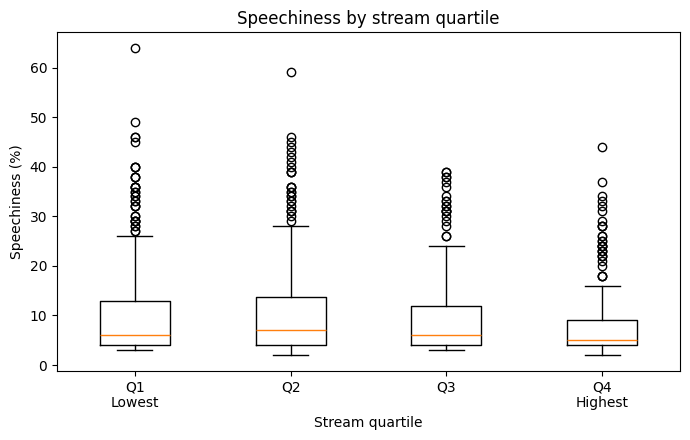

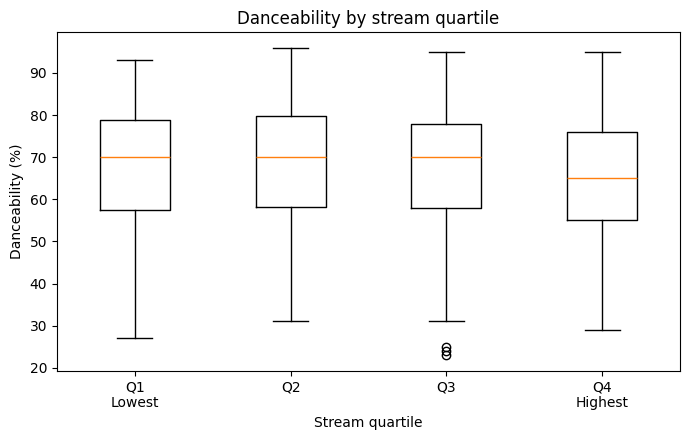

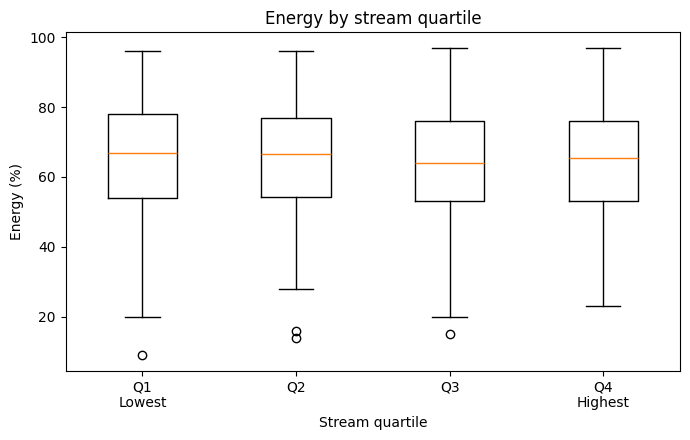

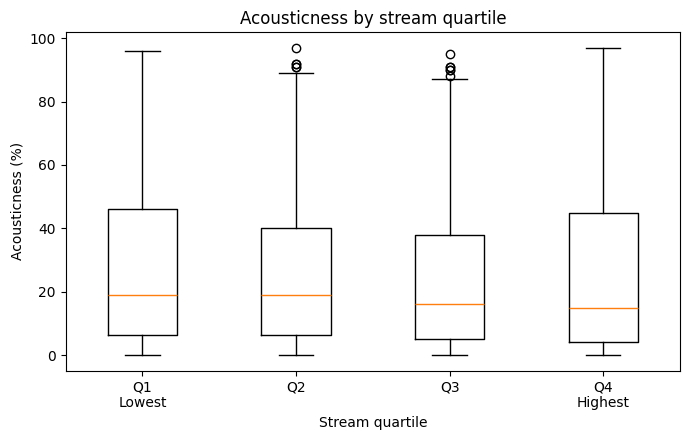

In [7]:
plot_features = [
    ("speechiness_%", "Speechiness (%)"),
    ("danceability_%", "Danceability (%)"),
    ("energy_%", "Energy (%)"),
    ("acousticness_%", "Acousticness (%)")
]

for feature, ylab in plot_features:
    groups = [
        df_analysis.loc[
            df_analysis["stream_quartile"] == q,
            feature
        ].dropna()
        for q in df_analysis["stream_quartile"].cat.categories
    ]

    plt.figure(figsize=(7, 4.5))
    plt.boxplot(
        groups,
        tick_labels=["Q1\nLowest", "Q2", "Q3", "Q4\nHighest"]
    )
    plt.xlabel("Stream quartile")
    plt.ylabel(ylab)
    plt.title(f"{ylab.replace(' (%)', '')} by stream quartile")
    plt.tight_layout()
    plt.savefig(
        output_dir / f"{feature.replace('%', 'pct')}_by_quartile.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


### How I am reading the boxplots

For each feature, the four boxes correspond to the four **stream groups** (Q1 to Q4). The line inside each box is the median, and the box itself contains the middle 50% of the feature values. The whiskers show the usual spread beyond the box, while the circles are possible outliers.

What I am mainly looking for is whether the median and the whole box move up or down across Q1 to Q4, and how much the boxes overlap.

- **Speechiness:** Q4 sits lower than the other groups, so the highest-streamed songs generally have lower speechiness. There are also several high speechiness outliers, especially in the lower stream groups.
- **Danceability:** Q1, Q2 and Q3 look fairly similar, while Q4 has a somewhat lower median. There is still a lot of overlap.
- **Energy:** the boxes overlap heavily, so there is no obvious visual separation across the four stream groups.
- **Acousticness:** there is also a lot of overlap, so any difference is not very clear from the boxplot alone.

The boxplots are only a visual check. I use the Kruskal-Wallis test next to see whether there is statistical evidence of a difference across the four groups.


In [8]:
# Exact values behind the boxes, so I do not have to estimate only from the graph
box_summary_rows = []

for feature, label in plot_features:
    for q in df_analysis["stream_quartile"].cat.categories:
        s = df_analysis.loc[df_analysis["stream_quartile"] == q, feature].dropna()
        box_summary_rows.append({
            "Feature": label,
            "Stream group": q,
            "25th percentile": s.quantile(0.25),
            "Median": s.median(),
            "75th percentile": s.quantile(0.75)
        })

box_summary = pd.DataFrame(box_summary_rows).round(2)
display(box_summary)


,Feature,Stream group,25th percentile,Median,75th percentile
0,Speechiness (%),Q1: Lowest 25%,4.00,6.0,13.00
1,Speechiness (%),Q2,4.00,7.0,13.75
2,Speechiness (%),Q3,4.00,6.0,12.00
3,Speechiness (%),Q4: Highest 25%,4.00,5.0,9.00
4,Danceability (%),Q1: Lowest 25%,57.50,70.0,78.75
5,Danceability (%),Q2,58.25,70.0,79.75
6,Danceability (%),Q3,58.00,70.0,78.00
7,Danceability (%),Q4: Highest 25%,55.00,65.0,76.00
8,Energy (%),Q1: Lowest 25%,54.00,67.0,78.00
9,Energy (%),Q2,54.25,66.5,77.00


## Kruskal-Wallis test

Since some of the audio features are skewed, I used a **Kruskal-Wallis test** instead of comparing the four groups with a standard one-way ANOVA.

For each feature, the null hypothesis is that its distribution is the same across Q1, Q2, Q3, and Q4.


In [9]:
results = []

for feature in features:
    groups = [
        df_analysis.loc[
            df_analysis["stream_quartile"] == q,
            feature
        ].dropna()
        for q in df_analysis["stream_quartile"].cat.categories
    ]

    H, p = kruskal(*groups)

    results.append({
        "Feature": feature,
        "H statistic": round(H, 3),
        "p-value": round(p, 4)
    })

kw_results = pd.DataFrame(results).sort_values("p-value")

kw_results["Result at 0.05"] = np.where(
    kw_results["p-value"] < 0.05,
    "Evidence of a difference",
    "No significant evidence"
)

display(kw_results)

kw_results.to_csv(output_dir / "kruskal_wallis_results.csv", index=False)


,Feature,H statistic,p-value,Result at 0.05
7,speechiness_%,16.248,0.0010,Evidence of a difference
1,danceability_%,9.068,0.0284,Evidence of a difference
2,valence_%,5.538,0.1364,No significant evidence
4,acousticness_%,2.788,0.4254,No significant evidence
6,liveness_%,2.715,0.4377,No significant evidence
0,bpm,2.441,0.4861,No significant evidence
3,energy_%,2.242,0.5237,No significant evidence
5,instrumentalness_%,1.325,0.7233,No significant evidence


The smallest p-value is for **speechiness**, followed by **danceability**. At the 0.05 level, those are the two features that show evidence of a difference across the four stream groups.


### Which stream groups are different?

The Kruskal-Wallis test tells me that at least one of the four groups is different, but it does not tell me which groups differ from each other.

Since speechiness and danceability had p-values below 0.05, I followed them with a **Dunn post-hoc test**. This compares the stream quartiles two at a time. Because there are six pairwise comparisons for each feature, I used the **Holm adjustment** on those p-values.


In [10]:
def dunn_posthoc(data, value_col, group_col):
    d = data[[value_col, group_col]].dropna().copy()
    d["rank"] = rankdata(d[value_col].to_numpy(), method="average")
    N = len(d)

    groups = list(d[group_col].cat.categories)
    mean_ranks = d.groupby(group_col, observed=True)["rank"].mean()
    group_sizes = d.groupby(group_col, observed=True).size()

    counts = d[value_col].value_counts()
    tie_sum = np.sum(counts**3 - counts)
    variance_base = (N * (N + 1) / 12) - (tie_sum / (12 * (N - 1)))

    rows = []
    for g1, g2 in itertools.combinations(groups, 2):
        z = (mean_ranks[g1] - mean_ranks[g2]) / np.sqrt(
            variance_base * (1/group_sizes[g1] + 1/group_sizes[g2])
        )
        p = 2 * norm.sf(abs(z))
        rows.append({"Group 1": g1, "Group 2": g2, "z": z, "p-value": p})

    out = pd.DataFrame(rows)

    m = len(out)
    order = np.argsort(out["p-value"].to_numpy())
    sorted_p = out["p-value"].to_numpy()[order]
    holm_sorted = np.maximum.accumulate((m - np.arange(m)) * sorted_p)
    holm_sorted = np.minimum(holm_sorted, 1.0)
    holm = np.empty(m)
    holm[order] = holm_sorted

    out["Holm-adjusted p"] = holm
    out["Result"] = np.where(out["Holm-adjusted p"] < 0.05, "Significant", "Not significant")
    return out.sort_values("p-value").reset_index(drop=True)

speech_posthoc = dunn_posthoc(df_analysis, "speechiness_%", "stream_quartile")
dance_posthoc = dunn_posthoc(df_analysis, "danceability_%", "stream_quartile")

posthoc_results = pd.concat([
    speech_posthoc.assign(Feature="Speechiness"),
    dance_posthoc.assign(Feature="Danceability")
], ignore_index=True)

display(posthoc_results[[
    "Feature", "Group 1", "Group 2", "z", "p-value", "Holm-adjusted p", "Result"
]].round(4))


Feature,Group 1,Group 2,z,p-value,Holm-adjusted p,Result
Speechiness,Q2,Q4: Highest 25%,3.7925,0.0001,0.0009,Significant
Speechiness,Q1: Lowest 25%,Q4: Highest 25%,3.0367,0.0024,0.0120,Significant
Speechiness,Q3,Q4: Highest 25%,1.9810,0.0476,0.1904,Not significant
Speechiness,Q2,Q3,1.8115,0.0701,0.2102,Not significant
Speechiness,Q1: Lowest 25%,Q3,1.0557,0.2911,0.5822,Not significant
Speechiness,Q1: Lowest 25%,Q2,-0.7557,0.4498,0.5822,Not significant
Danceability,Q2,Q4: Highest 25%,2.8528,0.0043,0.0260,Significant
Danceability,Q1: Lowest 25%,Q4: Highest 25%,2.1287,0.0333,0.1664,Not significant
Danceability,Q3,Q4: Highest 25%,2.0862,0.0370,0.1664,Not significant
Danceability,Q2,Q3,0.7666,0.4433,1.0000,Not significant


For **speechiness**, Q4 is significantly different from Q1 and Q2 after the Holm adjustment. This helps explain the Kruskal-Wallis result: the highest-stream group has lower speechiness than those two groups.

For **danceability**, the significant pairwise difference is Q2 versus Q4. The other pairwise comparisons are not significant after the adjustment.


## Do the relationships between features change too?

The Kruskal-Wallis tests look at one audio feature at a time. I also wanted to check whether the **relationships between the features** change across stream levels.

I calculated a separate Pearson correlation matrix for **each** stream quartile: Q1, Q2, Q3 and Q4. I am showing all four here so that the middle groups are not being skipped.


In [11]:
correlation_matrices = {}

for q in df_analysis["stream_quartile"].cat.categories:
    subset = df_analysis.loc[df_analysis["stream_quartile"] == q, features]
    correlation_matrices[q] = subset.corr()

for q in df_analysis["stream_quartile"].cat.categories:
    print(f"\n{q}")
    display(correlation_matrices[q].round(2))

corr_q1 = correlation_matrices["Q1: Lowest 25%"]
corr_q4 = correlation_matrices["Q4: Highest 25%"]



Q1: Lowest 25%


,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
bpm,1.00,0.03,0.03,0.15,-0.12,0.05,-0.10,-0.02
danceability_%,0.03,1.00,0.37,0.23,-0.25,0.02,-0.18,0.09
valence_%,0.03,0.37,1.00,0.37,-0.02,-0.13,-0.04,0.09
energy_%,0.15,0.23,0.37,1.00,-0.55,-0.04,0.07,-0.03
acousticness_%,-0.12,-0.25,-0.02,-0.55,1.00,0.02,-0.08,0.02
instrumentalness_%,0.05,0.02,-0.13,-0.04,0.02,1.00,-0.03,-0.09
liveness_%,-0.10,-0.18,-0.04,0.07,-0.08,-0.03,1.00,-0.08
speechiness_%,-0.02,0.09,0.09,-0.03,0.02,-0.09,-0.08,1.00



Q2


,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
bpm,1.00,-0.13,0.09,0.05,-0.10,-0.10,0.10,0.01
danceability_%,-0.13,1.00,0.38,0.05,-0.18,-0.04,0.00,0.18
valence_%,0.09,0.38,1.00,0.30,-0.04,-0.10,0.06,-0.05
energy_%,0.05,0.05,0.30,1.00,-0.55,-0.13,0.21,-0.10
acousticness_%,-0.10,-0.18,-0.04,-0.55,1.00,0.18,-0.11,-0.08
instrumentalness_%,-0.10,-0.04,-0.10,-0.13,0.18,1.00,-0.04,-0.10
liveness_%,0.10,0.00,0.06,0.21,-0.11,-0.04,1.00,-0.02
speechiness_%,0.01,0.18,-0.05,-0.10,-0.08,-0.10,-0.02,1.00



Q3


,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
bpm,1.00,-0.17,0.15,-0.12,0.10,0.01,-0.05,0.14
danceability_%,-0.17,1.00,0.37,0.31,-0.30,-0.15,-0.03,0.23
valence_%,0.15,0.37,1.00,0.34,-0.01,-0.20,0.07,0.08
energy_%,-0.12,0.31,0.34,1.00,-0.54,-0.01,0.14,0.06
acousticness_%,0.10,-0.30,-0.01,-0.54,1.00,0.02,0.01,0.01
instrumentalness_%,0.01,-0.15,-0.20,-0.01,0.02,1.00,-0.09,-0.07
liveness_%,-0.05,-0.03,0.07,0.14,0.01,-0.09,1.00,-0.03
speechiness_%,0.14,0.23,0.08,0.06,0.01,-0.07,-0.03,1.00



Q4: Highest 25%


,bpm,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
bpm,1.00,-0.30,-0.10,0.04,0.04,0.04,0.03,0.05
danceability_%,-0.30,1.00,0.50,0.21,-0.22,-0.21,-0.12,0.24
valence_%,-0.10,0.50,1.00,0.42,-0.25,-0.10,-0.02,0.02
energy_%,0.04,0.21,0.42,1.00,-0.67,0.05,0.03,0.08
acousticness_%,0.04,-0.22,-0.25,-0.67,1.00,-0.07,-0.01,-0.07
instrumentalness_%,0.04,-0.21,-0.10,0.05,-0.07,1.00,0.00,-0.10
liveness_%,0.03,-0.12,-0.02,0.03,-0.01,0.00,1.00,0.05
speechiness_%,0.05,0.24,0.02,0.08,-0.07,-0.10,0.05,1.00


### Compare all feature pairs

With 8 audio features there are 28 unique pairs. I did not want to choose only a few pairs just because they looked interesting, so I summarized **all 28** and compared their correlations in Q1, Q2, Q3 and Q4.

The last two columns show the numerical change from Q1 to Q4. This is still descriptive: a larger change here does **not** automatically mean the two correlations are statistically significantly different.


In [12]:
pair_rows = []

for f1, f2 in itertools.combinations(features, 2):
    q1 = correlation_matrices["Q1: Lowest 25%"].loc[f1, f2]
    q2 = correlation_matrices["Q2"].loc[f1, f2]
    q3 = correlation_matrices["Q3"].loc[f1, f2]
    q4 = correlation_matrices["Q4: Highest 25%"].loc[f1, f2]

    pair_rows.append({
        "Feature 1": f1,
        "Feature 2": f2,
        "Q1": q1,
        "Q2": q2,
        "Q3": q3,
        "Q4": q4,
        "Q4 - Q1": q4 - q1,
        "Absolute change": abs(q4 - q1)
    })

all_pair_correlations = (
    pd.DataFrame(pair_rows)
    .sort_values("Absolute change", ascending=False)
    .reset_index(drop=True)
)

display(all_pair_correlations.round(3))
all_pair_correlations.to_csv(output_dir / "all_pairwise_correlations_by_quartile.csv", index=False)


,Feature 1,Feature 2,Q1,Q2,Q3,Q4,Q4 - Q1,Absolute change
0,bpm,danceability_%,0.026,-0.126,-0.172,-0.302,-0.328,0.328
1,danceability_%,instrumentalness_%,0.023,-0.043,-0.151,-0.209,-0.232,0.232
2,valence_%,acousticness_%,-0.017,-0.043,-0.006,-0.246,-0.229,0.229
3,bpm,acousticness_%,-0.123,-0.099,0.097,0.040,0.163,0.163
4,danceability_%,speechiness_%,0.088,0.184,0.228,0.237,0.149,0.149
5,liveness_%,speechiness_%,-0.084,-0.017,-0.031,0.047,0.131,0.131
6,bpm,valence_%,0.027,0.089,0.147,-0.102,-0.130,0.130
7,bpm,liveness_%,-0.096,0.102,-0.051,0.033,0.129,0.129
8,danceability_%,valence_%,0.369,0.378,0.372,0.498,0.129,0.129
9,energy_%,acousticness_%,-0.553,-0.551,-0.543,-0.671,-0.118,0.118


Some correlations differ numerically across Q1, Q2, Q3 and Q4. I use a formal comparison test later to determine whether these differences in correlation are statistically significant.


### Correlation heatmaps for all four stream groups

I used the same -1 to 1 scale on every heatmap. That way, the colors mean the same thing in Q1, Q2, Q3 and Q4 and I can compare them directly.


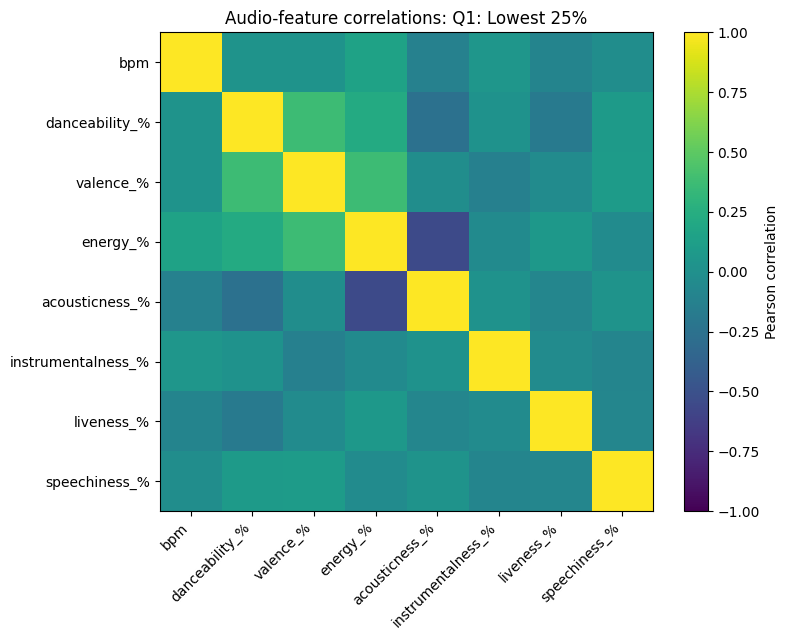

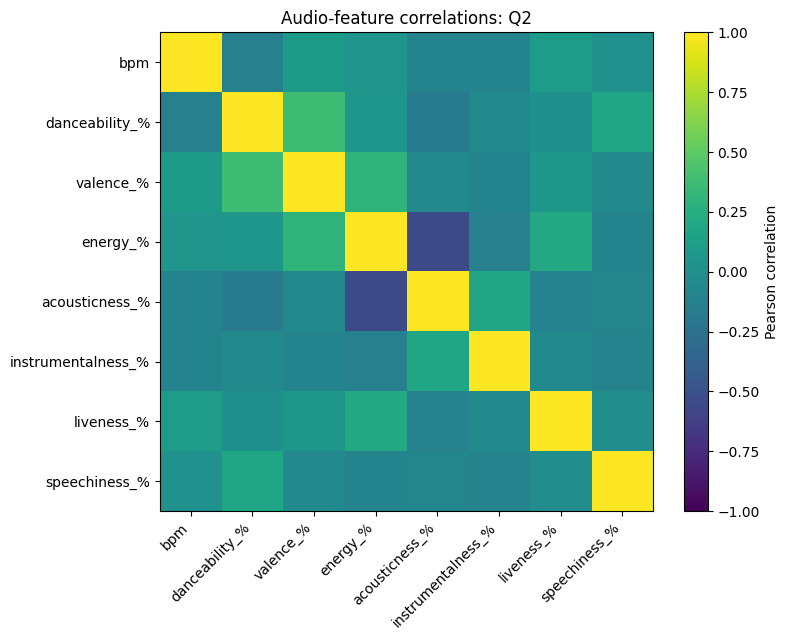

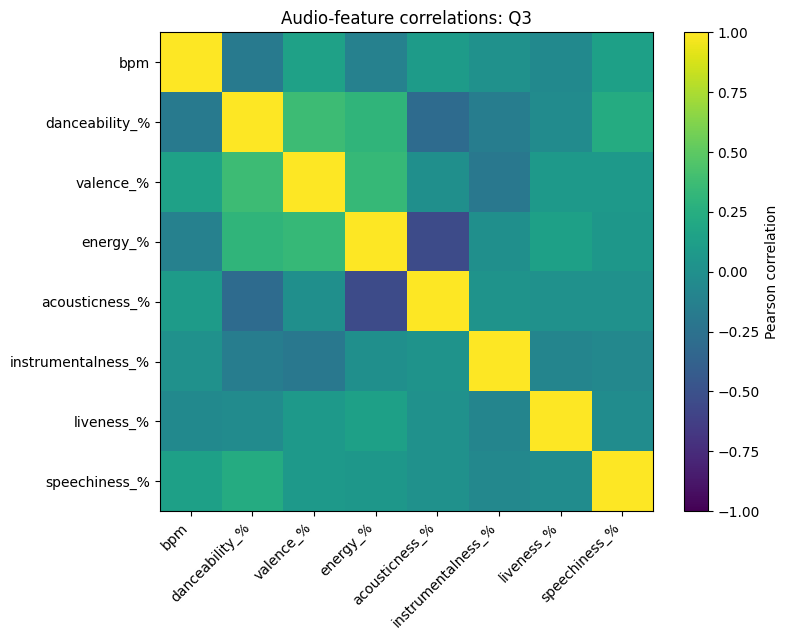

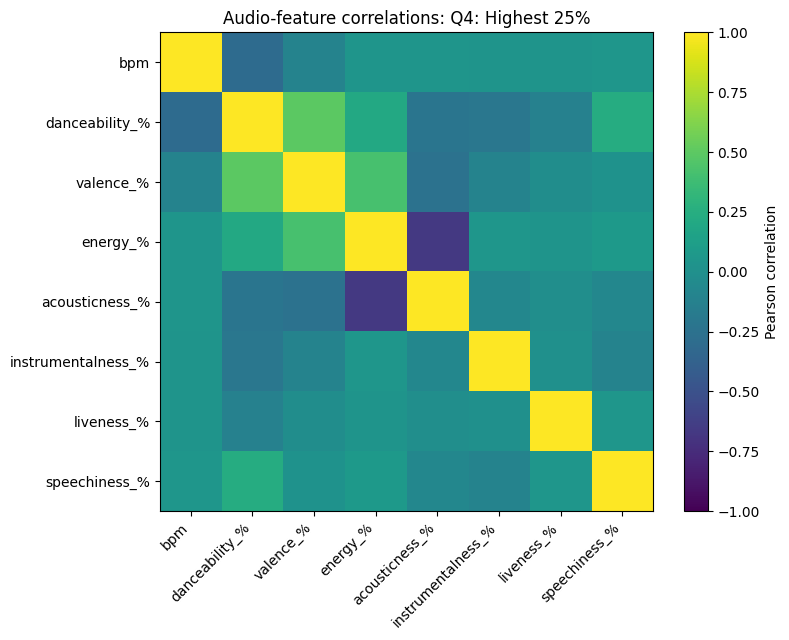

In [13]:
for q in df_analysis["stream_quartile"].cat.categories:
    corr = correlation_matrices[q]
    plt.figure(figsize=(8, 6.5))
    plt.imshow(corr, vmin=-1, vmax=1, aspect="auto")
    plt.xticks(range(len(features)), features, rotation=45, ha="right")
    plt.yticks(range(len(features)), features)
    plt.colorbar(label="Pearson correlation")
    plt.title(f"Audio-feature correlations: {q}")
    plt.tight_layout()
    plt.show()


### Two relationships I still find useful to visualize

After looking at the full table, I kept energy vs acousticness and danceability vs valence as scatterplot examples because they are among the clearest strong negative and positive relationships in Q4. The full 28-pair table above is what keeps the analysis from depending only on these two examples.


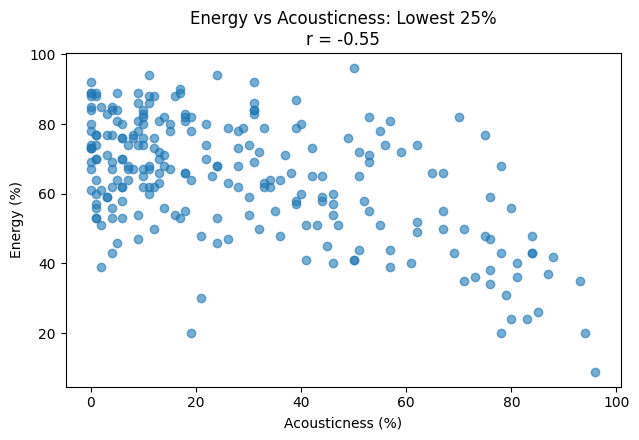

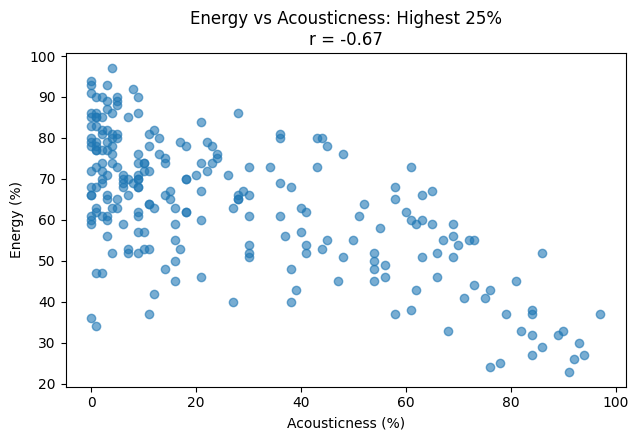

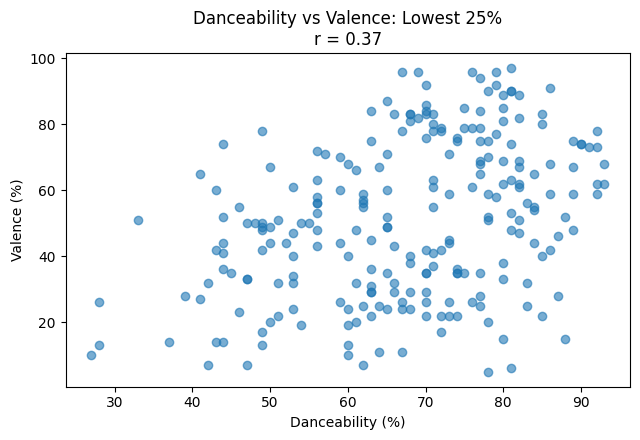

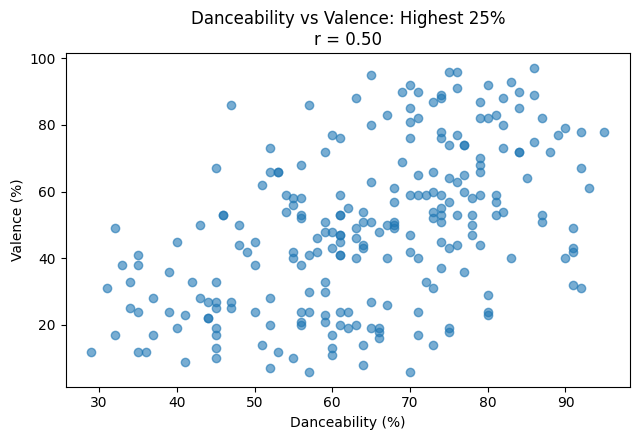

In [14]:
for q, short_label in [
    ("Q1: Lowest 25%", "Lowest 25%"),
    ("Q4: Highest 25%", "Highest 25%")
]:
    subset = df_analysis[df_analysis["stream_quartile"] == q]
    r = subset["energy_%"].corr(subset["acousticness_%"])

    plt.figure(figsize=(6.5, 4.5))
    plt.scatter(subset["acousticness_%"], subset["energy_%"], alpha=0.6)
    plt.xlabel("Acousticness (%)")
    plt.ylabel("Energy (%)")
    plt.title(f"Energy vs Acousticness: {short_label}\nr = {r:.2f}")
    plt.tight_layout()
    plt.show()

for q, short_label in [
    ("Q1: Lowest 25%", "Lowest 25%"),
    ("Q4: Highest 25%", "Highest 25%")
]:
    subset = df_analysis[df_analysis["stream_quartile"] == q]
    r = subset["danceability_%"].corr(subset["valence_%"])

    plt.figure(figsize=(6.5, 4.5))
    plt.scatter(subset["danceability_%"], subset["valence_%"], alpha=0.6)
    plt.xlabel("Danceability (%)")
    plt.ylabel("Valence (%)")
    plt.title(f"Danceability vs Valence: {short_label}\nr = {r:.2f}")
    plt.tight_layout()
    plt.show()


### Formal comparison of the correlations

The correlation values can look different across Q1, Q2, Q3 and Q4, so I tested whether those differences are statistically significant.

For each of the 28 feature pairs, I tested

$$H_0:\rho_{Q1}=\rho_{Q2}=\rho_{Q3}=\rho_{Q4}$$

against the alternative that at least one of the four correlations is different. I used Fisher's $r$-to-$z$ transformation for the comparison. Since there are 28 separate feature-pair tests, I applied the Holm adjustment to the p-values.


In [15]:
def compare_four_correlations(r_values, n_values):
    z_values = np.arctanh(np.clip(np.asarray(r_values), -0.999999, 0.999999))
    weights = np.asarray(n_values) - 3
    z_bar = np.sum(weights * z_values) / np.sum(weights)
    statistic = np.sum(weights * (z_values - z_bar) ** 2)
    p_value = chi2.sf(statistic, df=len(r_values) - 1)
    return statistic, p_value

groups = list(df_analysis["stream_quartile"].cat.categories)
group_sizes = {
    q: (df_analysis["stream_quartile"] == q).sum()
    for q in groups
}

test_rows = []
for f1, f2 in itertools.combinations(features, 2):
    r_values = [correlation_matrices[q].loc[f1, f2] for q in groups]
    n_values = [group_sizes[q] for q in groups]
    stat, p = compare_four_correlations(r_values, n_values)

    test_rows.append({
        "Feature 1": f1,
        "Feature 2": f2,
        "Q1": r_values[0],
        "Q2": r_values[1],
        "Q3": r_values[2],
        "Q4": r_values[3],
        "Test statistic": stat,
        "p-value": p
    })

correlation_tests = pd.DataFrame(test_rows)

m = len(correlation_tests)
order = np.argsort(correlation_tests["p-value"].to_numpy())
sorted_p = correlation_tests["p-value"].to_numpy()[order]
holm_sorted = np.maximum.accumulate((m - np.arange(m)) * sorted_p)
holm_sorted = np.minimum(holm_sorted, 1.0)
holm = np.empty(m)
holm[order] = holm_sorted

correlation_tests["Holm-adjusted p"] = holm
correlation_tests["Result"] = np.where(
    correlation_tests["Holm-adjusted p"] < 0.05,
    "Significant",
    "Not significant"
)

correlation_tests = correlation_tests.sort_values("p-value").reset_index(drop=True)
display(correlation_tests.round(4))


Feature 1,Feature 2,Q1,Q2,Q3,Q4,Test statistic,p-value,Holm-adjusted p,Result
bpm,danceability_%,0.0263,-0.1255,-0.1720,-0.3019,13.6951,0.0034,0.0938,Not significant
valence_%,acousticness_%,-0.0170,-0.0425,-0.0060,-0.2458,9.4155,0.0242,0.6547,Not significant
bpm,energy_%,0.1516,0.0461,-0.1179,0.0397,8.8010,0.0321,0.8335,Not significant
danceability_%,energy_%,0.2264,0.0494,0.3055,0.2076,8.7041,0.0335,0.8374,Not significant
bpm,valence_%,0.0275,0.0886,0.1473,-0.1022,8.1322,0.0434,1.0000,Not significant
bpm,acousticness_%,-0.1228,-0.0994,0.0972,0.0404,8.1033,0.0439,1.0000,Not significant
acousticness_%,instrumentalness_%,0.0203,0.1818,0.0239,-0.0712,7.9259,0.0476,1.0000,Not significant
danceability_%,instrumentalness_%,0.0234,-0.0430,-0.1507,-0.2086,7.8862,0.0484,1.0000,Not significant
energy_%,acousticness_%,-0.5525,-0.5512,-0.5432,-0.6705,6.7094,0.0818,1.0000,Not significant
bpm,liveness_%,-0.0962,0.1017,-0.0509,0.0332,5.4937,0.1390,1.0000,Not significant


The smallest unadjusted p-value is for **BPM vs danceability** ($p=0.0034$), but after the Holm adjustment it becomes $0.0938$.

Therefore, none of the 28 correlation differences are statistically significant at the 0.05 level after the adjustment. The heatmaps and scatterplots still show the numerical relationships in the data, but there is not enough evidence here to conclude that the correlations change across stream levels.


## Statistical Summary

The Kruskal-Wallis test shows that **speechiness** and **danceability** differ across the four stream groups at the 0.05 level.

The Dunn post-hoc test shows where those differences occur. For speechiness, Q4 differs significantly from Q1 and Q2. For danceability, the significant pairwise difference is between Q2 and Q4.

I also compared the correlations between the audio features across Q1, Q2, Q3 and Q4. Some correlation values change numerically, but after the formal correlation comparison and Holm adjustment, none of the 28 correlation differences are statistically significant at the 0.05 level.

So the clearest statistical differences across stream levels in this analysis are in the individual audio features, especially speechiness, rather than in the correlations between the audio features.
